# Do older players cross transfer community boundaries more often?

Among transfers **out of the same club in the same recorded season**, are
players aged **30+** more likely than players **under 30** to move outside
their origin club's historical transfer community?

This notebook implements the [analysis strategy](../data/dataset_graph/analysis_strategy.md)
in `exploration.ipynb`, as requested. Club IDs identify nodes; club names are
display labels. Each retained record counts once, irrespective of its fee.
Communities use only historical transfers (2017–2022); the age comparison
uses later transfers (2022–2025). Unknown historical ages remain in the graph.

The primary estimand is the overlap-weighted difference in crossing shares,
**30+ minus under 30**, in percentage points. Positive differences support
the proposed direction; the within-club-season permutation baseline measures
how unusual the observed difference is under exchangeable age labels.
Source files remain read-only. All checks and results run in cell order.

**Prefer pictures?** Run **Run All**, then jump to the
[visual sanity checks](#visual-sanity-checks) at the end. Start with the
age difference and shuffled baseline; the following figures explain who
enters the comparison, what the communities look like, and what changes
under alternative choices. The original calculations remain above.

In [42]:
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import normalized_mutual_info_score

ROOT = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / 'pnas_report/data/dataset_graph/cleaned_transfers_with_players.csv.gz').is_file()
)
DATA_PATH = ROOT / 'pnas_report/data/dataset_graph/cleaned_transfers_with_players.csv.gz'
SEED = 42
N_SHUFFLES = 999
HISTORICAL_SEASONS = ['17/18', '18/19', '19/20', '20/21', '21/22']
EVALUATION_SEASONS = ['22/23', '23/24', '24/25']
PLACEHOLDERS = {75: 'Unknown', 123: 'Retired', 515: 'Without Club',
                2113: 'Career break', 24067: 'School Team'}
STRATA = ['from_club_id', 'transfer_season']

plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_colwidth', 160)
print(f'Input: {DATA_PATH.relative_to(ROOT)}')
print(f'Python: {platform.python_version()} | seed: {SEED} | shuffles: {N_SHUFFLES}')
display(pd.Series({name: version(name) for name in
                   ['pandas', 'numpy', 'networkx', 'matplotlib', 'scikit-learn']},
                  name='Installed version').to_frame())

Input: pnas_report\data\dataset_graph\cleaned_transfers_with_players.csv.gz
Python: 3.12.14 | seed: 42 | shuffles: 999


,Installed version
pandas,3.0.5
numpy,2.5.4
networkx,3.7
matplotlib,3.11.2
scikit-learn,1.9.1


## 1. Audit the input and split the seasons

**Question:** Which records enter each window, and which exclusions affect
the comparison? The [dataset context](../data/dataset_graph/context.md)
describes the club-to-club links. The cleaned file already applies the
[club-ID exclusion rules](../data/exclusion_criteria.md), including youth,
academy, junior, reserve and second-team name matches. These literal rules
also remove some senior clubs (for example Boca Juniors); this limits the
population represented here. We verify those exclusions rather than apply
a new name-based filter.

We inspect repeated `(player_id, transfer_date, from_club_id, to_club_id)`
keys before counting records. We then remove missing endpoints, invalid
dates, self-transfers, and the five specified placeholder IDs. Both recorded
season **and** date must satisfy their window. The file has no transfer-type
field, so loans and permanent moves cannot be distinguished; fees are unused.

In [43]:
raw = pd.read_csv(DATA_PATH, dtype={
    'player_id': 'Int64', 'from_club_id': 'Int64', 'to_club_id': 'Int64',
    'transfer_season': 'string',
}, low_memory=False)
transfers = raw.copy()
transfers['transfer_date'] = pd.to_datetime(raw['transfer_date'], errors='coerce')
numeric_age = pd.to_numeric(raw['age_when_transferred'], errors='coerce')
transfers['age'] = numeric_age.where(np.isfinite(numeric_age))
assert transfers['age'].dropna().ge(0).all()

key = ['player_id', 'transfer_date', 'from_club_id', 'to_club_id']
repeated = transfers.loc[transfers.duplicated(key, keep=False)]
audit = pd.Series({
    'Input transfer records': len(transfers),
    'Distinct players': transfers['player_id'].nunique(),
    'Records missing an endpoint ID': transfers[['from_club_id', 'to_club_id']].isna().any(axis=1).sum(),
    'Invalid or missing transfer dates': transfers['transfer_date'].isna().sum(),
    'Missing or unparseable ages': transfers['age'].isna().sum(),
    'Nonmissing ages that failed numeric parsing': (raw['age_when_transferred'].notna() & transfers['age'].isna()).sum(),
    'Records in repeated transfer keys': len(repeated),
    'Excess records beyond one per key': transfers.duplicated(key).sum(),
}, name='Count')
display(audit.to_frame())
if not repeated.empty:
    display(repeated[key + ['player_name', 'from_club_name', 'to_club_name', 'age']].head(20))
    print('Repeated keys retained as individual records; inspect the examples before interpreting results.')
else:
    print('No repeated transfer keys: each input record represents a distinct audited key.')

excluded_ids = pd.read_csv(ROOT / 'pnas_report/data/exclusion_criteria.csv')['club_id']
assert not (transfers['from_club_id'].isin(excluded_ids)
            | transfers['to_club_id'].isin(excluded_ids)).any()
print('Previously applied club-ID exclusions verified: no excluded endpoint remains.')

,Count
Input transfer records,105644
Distinct players,18985
Records missing an endpoint ID,0
Invalid or missing transfer dates,0
Missing or unparseable ages,12
Nonmissing ages that failed numeric parsing,0
Records in repeated transfer keys,0
Excess records beyond one per key,0


No repeated transfer keys: each input record represents a distinct audited key.
Previously applied club-ID exclusions verified: no excluded endpoint remains.


In [44]:
ledger = [{'branch': 'Common', 'step': 'Cleaned input', 'removed': 0, 'remaining': len(transfers)}]

def retain(frame, mask, branch, step):
    kept = frame.loc[mask].copy()
    ledger.append({'branch': branch, 'step': step,
                   'removed': len(frame) - len(kept), 'remaining': len(kept)})
    return kept

base = retain(transfers, transfers[['from_club_id', 'to_club_id']].notna().all(axis=1),
              'Common', 'Known endpoint IDs')
base = retain(base, base['transfer_date'].notna(), 'Common', 'Valid transfer dates')
base = retain(base, base['from_club_id'].ne(base['to_club_id']), 'Common', 'Remove self-transfers')
base = retain(base, ~(base['from_club_id'].isin(PLACEHOLDERS)
                     | base['to_club_id'].isin(PLACEHOLDERS)), 'Common', 'Remove placeholder endpoints')

historical = retain(base, base['transfer_season'].isin(HISTORICAL_SEASONS),
                    'Historical', 'Recorded seasons 17/18–21/22 (from Common)')
historical = retain(historical, historical['transfer_date'].between('2017-07-01', '2022-06-30'),
                    'Historical', 'Dates 2017-07-01 through 2022-06-30')
evaluation = retain(base, base['transfer_season'].isin(EVALUATION_SEASONS),
                    'Evaluation', 'Recorded seasons 22/23–24/25 (from Common)')
evaluation = retain(evaluation, evaluation['transfer_date'].between('2022-07-01', '2025-06-30'),
                    'Evaluation', 'Dates 2022-07-01 through 2025-06-30')

display(pd.DataFrame(ledger))
print('The two window branches each start from the final Common rows; removals are not additive across branches.')
for branch in ['Historical', 'Evaluation']:
    date_step = next(row for row in ledger if row['branch'] == branch and row['step'].startswith('Dates'))
    print(f"{branch}: {date_step['removed']:,} records pass the recorded-season filter but fail its date window.")
display(pd.DataFrame([
    {'window': label, 'records': len(frame), 'earliest_date': frame['transfer_date'].min().date(),
     'latest_date': frame['transfer_date'].max().date(), 'missing_ages': frame['age'].isna().sum()}
    for label, frame in [('Historical', historical), ('Evaluation', evaluation)]
]))
season_counts = pd.concat({
    label: frame.groupby('transfer_season').agg(records=('player_id', 'size'), missing_ages=('age', lambda s: s.isna().sum()))
    for label, frame in [('Historical', historical), ('Evaluation', evaluation)]
}, names=['window'])
display(season_counts)

assert historical.index.intersection(evaluation.index).empty
assert historical['transfer_date'].max() < evaluation['transfer_date'].min()
assert set(historical['transfer_season']).isdisjoint(evaluation['transfer_season'])
assert len(historical) == 34_405 and len(evaluation) == 33_316, 'Snapshot counts differ from the strategy.'
print('Window checks passed: disjoint records and seasons, with every evaluation date after the historical window.')

,branch,step,removed,remaining
0,Common,Cleaned input,0,105644
1,Common,Known endpoint IDs,0,105644
2,Common,Valid transfer dates,0,105644
3,Common,Remove self-transfers,3,105641
4,Common,Remove placeholder endpoints,6596,99045
5,Historical,Recorded seasons 17/18–21/22 (from Common),64614,34431
6,Historical,Dates 2017-07-01 through 2022-06-30,26,34405
7,Evaluation,Recorded seasons 22/23–24/25 (from Common),65651,33394
8,Evaluation,Dates 2022-07-01 through 2025-06-30,78,33316


The two window branches each start from the final Common rows; removals are not additive across branches.
Historical: 26 records pass the recorded-season filter but fail its date window.
Evaluation: 78 records pass the recorded-season filter but fail its date window.


,window,records,earliest_date,latest_date,missing_ages
0,Historical,34405,2017-07-01,2022-06-30,3
1,Evaluation,33316,2022-07-01,2025-06-30,1


records  missing_ages
window     transfer_season                       
Historical 17/18               5209             0
           18/19               6116             0
           19/20               6946             2
           20/21               7329             0
           21/22               8805             1
Evaluation 22/23              10188             1
           23/24              11535             0
           24/25              11593             0

Window checks passed: disjoint records and seasons, with every evaluation date after the historical window.


## 2. Build and describe the historical graph

**Question:** How many clubs and distinct directed routes does the historical
transfer network contain? A link from A to B has weight equal to its retained
transfer count; a reverse link from B to A is separate. Degree counts distinct
partner clubs; strength counts transfer records. Names below are the most
frequent observed label for each club ID and do not influence the partition.

In [45]:
name_observations = pd.concat([
    transfers[['from_club_id', 'from_club_name']].set_axis(['club_id', 'club_name'], axis=1),
    transfers[['to_club_id', 'to_club_name']].set_axis(['club_id', 'club_name'], axis=1),
], ignore_index=True)
club_names = (name_observations.value_counts(['club_id', 'club_name']).rename('observations')
              .reset_index().sort_values(['observations', 'club_name'], ascending=[False, True])
              .drop_duplicates('club_id').set_index('club_id')['club_name'])

flows = historical.groupby(['from_club_id', 'to_club_id'], sort=True).size().rename('weight').reset_index()
graph = nx.from_pandas_edgelist(flows, 'from_club_id', 'to_club_id', 'weight', create_using=nx.DiGraph)
assert graph.is_directed()
assert graph.number_of_nodes() == 5_410
assert sum(nx.get_edge_attributes(graph, 'weight').values()) == len(historical)
display(pd.Series({'Club nodes': graph.number_of_nodes(), 'Directed links': graph.number_of_edges(),
                   'Historical transfer records (sum of weights)': len(historical)}, name='Count').to_frame())
largest_flows = flows.nlargest(10, 'weight').copy()
largest_flows.insert(1, 'from_club_name', largest_flows['from_club_id'].map(club_names))
largest_flows.insert(3, 'to_club_name', largest_flows['to_club_id'].map(club_names))
display(largest_flows.rename(columns={'weight': 'transfer_records'}).reset_index(drop=True))

toy_rows = pd.DataFrame({'from_club_id': [101, 101, 202], 'to_club_id': [202, 202, 101]})
toy_flows = toy_rows.groupby(['from_club_id', 'to_club_id']).size().rename('weight').reset_index()
toy_graph = nx.from_pandas_edgelist(toy_flows, 'from_club_id', 'to_club_id', 'weight', create_using=nx.DiGraph)
assert toy_graph[101][202]['weight'] == 2 and toy_graph[202][101]['weight'] == 1
assert sum(nx.get_edge_attributes(toy_graph, 'weight').values()) == 3
print('Hand check: fictional clubs 101 → 202 twice and 202 → 101 once give two directed links, weights 2 and 1.')
display(toy_flows)

,Count
Club nodes,5410
Directed links,27697
Historical transfer records (sum of weights),34405


,from_club_id,from_club_name,to_club_id,to_club_name,transfer_records
0,37024,FC Liefering,409,Salzburg,22
1,6993,FC Mariupol,660,Shakhtar D.,20
2,660,Shakhtar D.,6993,FC Mariupol,19
3,697,Slovan Liberec,62,Slavia Praha,16
4,62,Slavia Praha,697,Slovan Liberec,14
5,11194,NK Lokomotiva,419,Dinamo Zagreb,13
6,6688,Bilbao Athletic,621,Athletic Club,12
7,8816,Dallas,71021,North Texas SC,12
8,11610,Las Palmas Atl.,472,UD Las Palmas,12
9,43502,Chertanovo,2696,KS Samara,12


Hand check: fictional clubs 101 → 202 twice and 202 → 101 once give two directed links, weights 2 and 1.


,from_club_id,to_club_id,weight
0,101,202,2
1,202,101,1


In [48]:
club_metrics

,incoming_degree,outgoing_degree,incoming_strength,outgoing_strength
club_id,,,,
1,1,1,1,1
254,20,16,20,17
2,7,9,7,12
39,41,41,45,48
60,27,30,33,38
...,...,...,...,...
134965,0,1,0,1
137900,0,1,0,1
138626,0,1,0,1


,min,median,max
Club-level measure,,,
incoming_degree,0.0,1.0,91.0
outgoing_degree,0.0,2.0,78.0
incoming_strength,0.0,2.0,139.0
outgoing_strength,0.0,2.0,128.0


,Clubs with zero value
incoming_degree,1150
outgoing_degree,428
incoming_strength,1150
outgoing_strength,428


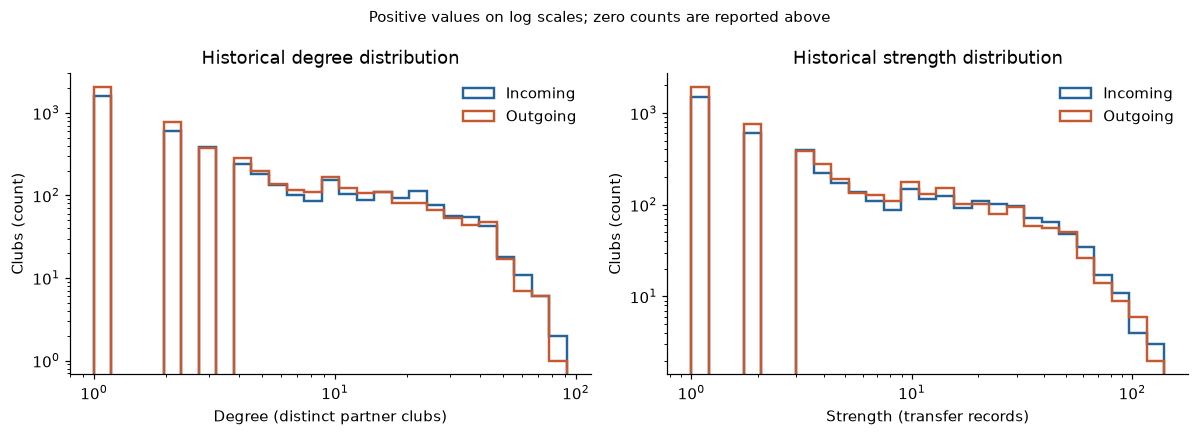

In [46]:
club_metrics = pd.DataFrame({
    'incoming_degree': dict(graph.in_degree()), 'outgoing_degree': dict(graph.out_degree()),
    'incoming_strength': dict(graph.in_degree(weight='weight')),
    'outgoing_strength': dict(graph.out_degree(weight='weight')),
}).rename_axis('club_id')
display(club_metrics.agg(['min', 'median', 'max']).T.rename_axis('Club-level measure'))
display(club_metrics.eq(0).sum().rename('Clubs with zero value').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, measure, unit in zip(axes, ['degree', 'strength'], ['distinct partner clubs', 'transfer records']):
    bins = np.geomspace(1, club_metrics.filter(like=measure).to_numpy().max() + 1, 28)
    for direction, color in [('incoming', '#24649a'), ('outgoing', '#c55a32')]:
        values = club_metrics[f'{direction}_{measure}']
        ax.hist(values[values > 0], bins=bins, histtype='step', linewidth=1.6,
                label=direction.title(), color=color)
    ax.set(xscale='log', yscale='log', xlabel=f'{measure.title()} ({unit})', ylabel='Clubs (count)',
           title=f'Historical {measure} distribution')
    ax.legend(frameon=False)
fig.suptitle('Positive values on log scales; zero counts are reported above', fontsize=10)
fig.tight_layout()
plt.show()

## 3. Define communities and measure who can be compared

**Question:** Which later transfers have two historically assigned endpoints,
and which origin-club seasons contain both age groups? Weighted Louvain uses
the **directed** historical graph, resolution **1.0**, seed **42**, and transfer
counts as weights. Neither ages nor evaluation links enter community fitting.
A crossing means the endpoints have different IDs in this one partition.
Community numbers are arbitrary labels, ordered here by community size.

In [47]:
def fit_louvain(seed, resolution):
    groups = nx.community.louvain_communities(graph, weight='weight', resolution=resolution, seed=seed)
    groups = sorted(groups, key=lambda group: (-len(group), min(group)))
    membership = {club: group_id for group_id, group in enumerate(groups) for club in group}
    assert sum(map(len, groups)) == len(membership) == graph.number_of_nodes()
    assert set(membership) == set(graph)
    return groups, membership

primary_communities, primary_map = fit_louvain(SEED, 1.0)
primary_modularity = nx.community.modularity(graph, primary_communities, weight='weight', resolution=1.0)
print(f'Primary communities: {len(primary_communities):,}; directed weighted modularity: {primary_modularity:.4f}')
community_sizes = pd.Series([len(group) for group in primary_communities], name='clubs').rename_axis('community')
print('All community sizes, in descending order:')
print(community_sizes.to_list())
display(community_sizes.describe().to_frame())

community_examples = []
total_strength = club_metrics['incoming_strength'] + club_metrics['outgoing_strength']
for group_id, clubs in enumerate(primary_communities[:8]):
    example_ids = total_strength.loc[list(clubs)].sort_values(ascending=False).head(4).index
    community_examples.append({'community': group_id, 'clubs': len(clubs),
                               'example_clubs (name [ID])': '; '.join(f'{club_names.loc[club]} [{club}]' for club in example_ids)})
display(pd.DataFrame(community_examples))

Primary communities: 196; directed weighted modularity: 0.6662
All community sizes, in descending order:
[426, 422, 404, 391, 366, 349, 288, 252, 252, 222, 220, 190, 185, 182, 164, 152, 139, 109, 93, 92, 27, 19, 11, 8, 8, 7, 6, 6, 6, 6, 5, 5, 5, 5, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


,clubs
count,196.000000
mean,27.602041
std,81.464825
min,2.000000
25%,2.000000
50%,2.000000
75%,4.000000
max,426.000000


,community,clubs,example_clubs (name [ID])
0,0,426,Salzburg [409]; Monaco [162]; RSC Anderlecht [58]; Club Brugge [2282]
1,1,422,Racing Club [1444]; Atl. Nacional [8172]; San Lorenzo [1775]; CA Talleres [3938]
2,2,404,Benfica [294]; Sporting [336]; Porto [720]; Palmeiras [1023]
3,3,391,Shakhtar D. [660]; Dynamo Kyiv [338]; Rostov [1083]; Rubin Kazan [2698]
4,4,366,Midtjylland [865]; Malmö [496]; Hammarby [1059]; Vejle BK [443]
5,5,349,Dallas [8816]; LAFC [51828]; Chicago [432]; Vancouver [6321]
6,6,288,Olympiacos [683]; Red Star [159]; PAOK [1091]; AEK Athens [2441]
7,7,252,Chelsea [631]; Wolves [543]; Celtic [371]; Everton [29]


In [30]:
assigned = evaluation.copy()
assigned['from_community'] = assigned['from_club_id'].map(primary_map).astype('Int64')
assigned['to_community'] = assigned['to_club_id'].map(primary_map).astype('Int64')
assigned['both_endpoints_assigned'] = assigned[['from_community', 'to_community']].notna().all(axis=1)
assigned['age_group'] = np.select([assigned['age'].isna(), assigned['age'].ge(30)],
                                 ['Unknown age', '30+'], default='Under 30')
for endpoint in ['from', 'to']:
    absent = ~assigned[f'{endpoint}_club_id'].isin(graph)
    assert assigned.loc[absent, f'{endpoint}_community'].isna().all()
    assert assigned.loc[~absent, f'{endpoint}_community'].notna().all()

coverage = (assigned.groupby(['transfer_season', 'age_group'])
            .agg(evaluation_records=('player_id', 'size'),
                 records_with_two_assigned_endpoints=('both_endpoints_assigned', 'sum')))
coverage['endpoint_coverage_percent'] = (100 * coverage['records_with_two_assigned_endpoints']
                                        / coverage['evaluation_records'])
print('Endpoint coverage denominator: all evaluation records in the named season and age group, before age or stratum exclusions.')
display(coverage.round(2))
print(f"Evaluation records with unknown age: {assigned['age'].isna().sum():,} / {len(assigned):,}")
print(f"Evaluation records touching an unseen club (any age): {(~assigned['both_endpoints_assigned']).sum():,} / {len(assigned):,}")

covered = retain(assigned, assigned['both_endpoints_assigned'], 'Evaluation', 'Two historical endpoint communities')
eligible = retain(covered, covered['age'].notna(), 'Evaluation', 'Known age among assigned endpoints')
eligible['older'] = eligible['age'].ge(30)
eligible['crossing'] = eligible['from_community'].ne(eligible['to_community']).astype(bool)

def mixed_age_strata(frame):
    group_variety = frame.groupby(STRATA)['older'].transform('nunique')
    return frame.loc[group_variety.eq(2)].copy()

comparison = mixed_age_strata(eligible)
ledger.append({'branch': 'Evaluation', 'step': 'Mixed-age origin club × recorded season',
               'removed': len(eligible) - len(comparison), 'remaining': len(comparison)})
stratum_count = comparison.groupby(STRATA).ngroups
assert len(eligible) == 30_753
assert stratum_count == 1_784 and len(comparison) == 17_748
assert comparison.groupby(STRATA)['older'].nunique().eq(2).all()
assert set(comparison.index).issubset(eligible.index)

print('Full filter ledger (branch steps remove rows from their preceding step):')
display(pd.DataFrame(ledger))
print(f'Mixed-age club-seasons: {stratum_count:,} / {eligible.groupby(STRATA).ngroups:,} with known age and two assigned endpoints')
display(pd.DataFrame({
    'Known age + assigned endpoints': eligible['age_group'].value_counts(),
    'Retained mixed-age club-seasons': comparison['age_group'].value_counts(),
}).rename_axis('Age group'))

examples = pd.concat([comparison.loc[comparison['crossing']].head(2),
                      comparison.loc[~comparison['crossing']].head(2)]).copy()
examples['from_club_name'] = examples['from_club_id'].map(club_names)
examples['to_club_name'] = examples['to_club_id'].map(club_names)
assert examples['crossing'].nunique() == 2
display(examples[['player_name', 'age', 'transfer_date', 'transfer_season',
                  'from_club_id', 'from_club_name', 'from_community',
                  'to_club_id', 'to_club_name', 'to_community', 'crossing']].reset_index(drop=True))

Endpoint coverage denominator: all evaluation records in the named season and age group, before age or stratum exclusions.


evaluation_records  \
transfer_season age_group                         
22/23           30+                         935   
                Under 30                   9252   
                Unknown age                   1   
23/24           30+                        1283   
                Under 30                  10252   
24/25           30+                        1533   
                Under 30                  10060   

                             records_with_two_assigned_endpoints  \
transfer_season age_group                                          
22/23           30+                                          922   
                Under 30                                    8683   
                Unknown age                                    1   
23/24           30+                                         1212   
                Under 30                                    9397   
24/25           30+                                         1430   
                Under 30                                    9109   

                             endpoint_coverage_percent  
transfer_season age_group                               
22/23           30+                              98.61  
                Under 30                         93.85  
                Unknown age                      100.0  
23/24           30+                              94.47  
                Under 30                         91.66  
24/25           30+                              93.28  
                Under 30                         90.55

Evaluation records with unknown age: 1 / 33,316
Evaluation records touching an unseen club (any age): 2,562 / 33,316
Full filter ledger (branch steps remove rows from their preceding step):


,branch,step,removed,remaining
0,Common,Cleaned input,0,105644
1,Common,Known endpoint IDs,0,105644
2,Common,Valid transfer dates,0,105644
3,Common,Remove self-transfers,3,105641
4,Common,Remove placeholder endpoints,6596,99045
5,Historical,Recorded seasons 17/18–21/22 (from Common),64614,34431
6,Historical,Dates 2017-07-01 through 2022-06-30,26,34405
7,Evaluation,Recorded seasons 22/23–24/25 (from Common),65651,33394
8,Evaluation,Dates 2022-07-01 through 2025-06-30,78,33316
9,Evaluation,Two historical endpoint communities,2562,30754


Mixed-age club-seasons: 1,784 / 6,462 with known age and two assigned endpoints


,Known age + assigned endpoints,Retained mixed-age club-seasons
Age group,,
Under 30,27189,14348
30+,3564,3400


,player_name,age,transfer_date,transfer_season,from_club_id,from_club_name,from_community,to_club_id,to_club_name,to_community,crossing
0,Sinan Bolat,36.0,2025-06-30,24/25,10484,Kasimpasa,13,968,KVC Westerlo,0,True
1,Borna Barisic,32.0,2025-06-30,24/25,1244,CD Leganés,14,449,Trabzonspor,13,True
2,Oriol Romeu,33.0,2025-06-30,24/25,12321,Girona,14,131,Barcelona,14,False
3,Rodolfo Cota,37.0,2025-06-30,24/25,3631,América,1,4941,León,1,False


## 4. Estimate the difference and compare it with a null model

**Question:** Among comparable club-seasons, how much higher is the crossing
share for older players, and is it unusual under shuffled age labels?

For stratum $s$, use $w_s=n_{30+,s}n_{<30,s}/(n_{30+,s}+n_{<30,s})$.
Each group's reported rate is $\sum_s w_s r_{g,s}/\sum_s w_s$.
The primary difference is $100(R_{30+}-R_{<30})$ percentage points.
These shared weights emphasize overlap between the groups; they do not
estimate the crossing rate of all transfers in the dataset.

We make **999 permutations of age-group labels within origin club and
recorded season**, preserving each stratum's age counts, transfers and
crossing outcomes. The community map stays fixed. The directional Monte
Carlo p-value is $(1+\#\{\Delta_b\geq\Delta_{obs}\})/(999+1)$.
This baseline assumes age labels are exchangeable within a club-season;
it does not establish a causal age effect or account for every player attribute.

In [31]:
def crossing_statistic(frame):
    strata = frame.groupby(STRATA, sort=True).agg(
        n_30plus=('older', 'sum'), n_total=('older', 'size'),
        crossings_total=('crossing', 'sum'),
    )
    strata['crossings_30plus'] = (frame['crossing'] & frame['older']).groupby(
        [frame[column] for column in STRATA], sort=True).sum()
    strata['n_under30'] = strata['n_total'] - strata['n_30plus']
    assert (strata[['n_30plus', 'n_under30']] > 0).all().all()
    strata['rate_30plus'] = strata['crossings_30plus'] / strata['n_30plus']
    strata['rate_under30'] = (strata['crossings_total'] - strata['crossings_30plus']) / strata['n_under30']
    strata['weight'] = strata['n_30plus'] * strata['n_under30'] / strata['n_total']
    older_rate = np.average(strata['rate_30plus'], weights=strata['weight'])
    younger_rate = np.average(strata['rate_under30'], weights=strata['weight'])
    return strata, older_rate, younger_rate, 100 * (older_rate - younger_rate)

def permutation_comparison(frame, n_shuffles=N_SHUFFLES, seed=SEED):
    strata, older_rate, younger_rate, difference = crossing_statistic(frame)
    rng = np.random.default_rng(seed)
    null_differences = np.zeros(n_shuffles)
    for stratum_key, group in frame.groupby(STRATA, sort=True):
        labels = group['older'].to_numpy(dtype=bool)
        crossings = group['crossing'].to_numpy(dtype=bool, copy=True)
        # Each row is a separate age-label permutation for this club-season.
        shuffled = rng.permuted(np.broadcast_to(labels, (n_shuffles, len(labels))), axis=1)
        n_older = labels.sum()
        n_younger = len(labels) - n_older
        assert np.all(shuffled.sum(axis=1) == n_older)
        older_crossings = shuffled[:, crossings].sum(axis=1)
        younger_crossings = crossings.sum() - older_crossings
        null_differences += strata.loc[stratum_key, 'weight'] * (
            older_crossings / n_older - younger_crossings / n_younger)
        assert np.array_equal(crossings, group['crossing'].to_numpy(dtype=bool))
    null_differences *= 100 / strata['weight'].sum()
    p_value = (1 + np.count_nonzero(null_differences >= difference)) / (1 + n_shuffles)
    result = {'strata': len(strata), 'transfers': len(frame), 'players': frame['player_id'].nunique(),
              'n_30plus': int(frame['older'].sum()), 'n_under30': int((~frame['older']).sum()),
              'rate_30plus_percent': 100 * older_rate, 'rate_under30_percent': 100 * younger_rate,
              'difference_pp': difference, 'null_mean_pp': null_differences.mean(),
              'null_2.5_percentile_pp': np.quantile(null_differences, 0.025),
              'null_97.5_percentile_pp': np.quantile(null_differences, 0.975),
              'one_sided_p': p_value, 'shuffles': n_shuffles}
    return result, null_differences, strata

### Hand check of the weighted statistic

**Question:** Does the calculation implement the stated weights? In fictional
stratum A, older players cross on 1/2 moves and younger players on 0/1;
its weight is $2/3$. In stratum B, the shares are 0/1 and 1/3, with weight
$3/4$. The total weight is $17/12$, giving weighted rates $4/17$ and $3/17$,
and a difference of $100/17\approx5.8824$ percentage points. We also shuffle
this example to verify fixed group counts and unchanged outcomes.

In [32]:
tiny = pd.DataFrame({
    'from_club_id': [101] * 3 + [202] * 4, 'transfer_season': ['toy'] * 7,
    'older': [True, True, False, True, False, False, False],
    'crossing': [True, False, False, False, True, False, False],
    'player_id': list(range(7)),
})
tiny_before = tiny.copy(deep=True)
tiny_strata, tiny_older, tiny_younger, tiny_difference = crossing_statistic(tiny)
assert np.isclose(tiny_older, 4 / 17) and np.isclose(tiny_younger, 3 / 17)
assert np.isclose(tiny_difference, 100 / 17)
tiny_result, tiny_null, _ = permutation_comparison(tiny, n_shuffles=19)
_, repeated_tiny_null, _ = permutation_comparison(tiny, n_shuffles=19)
pd.testing.assert_frame_equal(tiny, tiny_before)
np.testing.assert_array_equal(tiny_null, repeated_tiny_null)
display(tiny_strata[['n_30plus', 'n_under30', 'rate_30plus', 'rate_under30', 'weight']])
print(f'Hand check passed: 30+ = {100 * tiny_older:.4f}%, under 30 = {100 * tiny_younger:.4f}%, difference = {tiny_difference:.4f} pp.')
print('Permutation checks passed: reproducible draws, fixed age counts in every stratum, unchanged crossing outcomes.')

,,n_30plus,n_under30,rate_30plus,rate_under30,weight
from_club_id,transfer_season,,,,,
101,toy,2,1,0.5,0.000000,0.666667
202,toy,1,3,0.0,0.333333,0.750000


Hand check passed: 30+ = 23.5294%, under 30 = 17.6471%, difference = 5.8824 pp.
Permutation checks passed: reproducible draws, fixed age counts in every stratum, unchanged crossing outcomes.


Primary comparison: directed weighted Louvain, seed 42, resolution 1.0


,Primary result
strata,1784.0000
transfers,17748.0000
players,9782.0000
n_30plus,3400.0000
n_under30,14348.0000
rate_30plus_percent,40.7580
rate_under30_percent,39.7288
difference_pp,1.0293
null_mean_pp,-0.0238
null_2.5_percentile_pp,-1.7635


The null percentile range describes shuffled differences; it is not a confidence interval for the observed association.


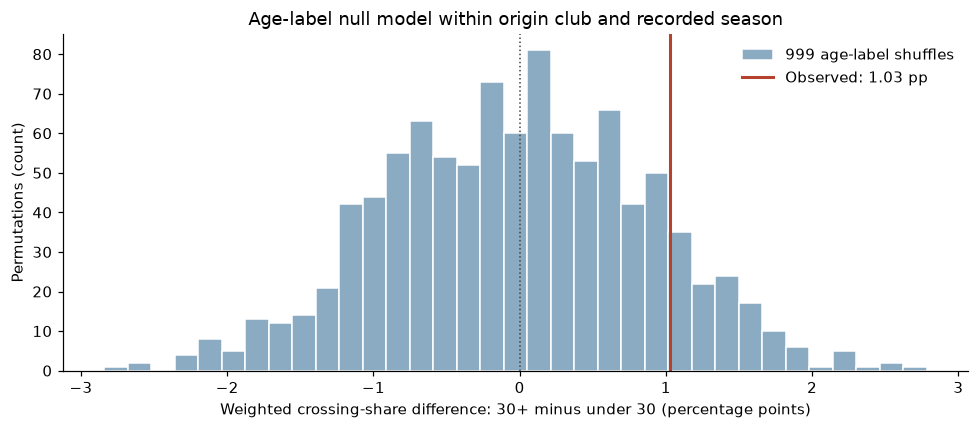

Largest overlap weights: stratum rates below are proportions (0–1).


,from_club_id,from_club_name,transfer_season,n_30plus,n_under30,rate_30plus,rate_under30,weight
51,36,Fenerbahçe,23/24,9,24,0.6667,0.5417,6.5455
52,36,Fenerbahçe,24/25,9,19,0.6667,0.6842,6.1071
1209,6646,Karagümrük,23/24,11,13,0.8182,0.3077,5.9583
443,609,Cruzeiro,24/25,8,21,0.5000,0.4762,5.7931
490,703,Nott'm Forest,23/24,7,29,0.7143,0.6552,5.6389
483,683,Olympiacos,24/25,7,28,0.5714,0.6429,5.6000
457,631,Chelsea,23/24,7,23,1.0000,0.5652,5.3667
1050,3840,Adana Demirspor,23/24,8,16,0.3750,0.5625,5.3333


In [33]:
primary_result, primary_null, primary_strata = permutation_comparison(comparison)
print('Primary comparison: directed weighted Louvain, seed 42, resolution 1.0')
display(pd.Series(primary_result, name='Primary result').to_frame().round(4))
print('The null percentile range describes shuffled differences; it is not a confidence interval for the observed association.')

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(primary_null, bins=35, color='#8aabc1', edgecolor='white', label=f'{N_SHUFFLES} age-label shuffles')
ax.axvline(primary_result['difference_pp'], color='#b4422d', linewidth=2,
           label=f"Observed: {primary_result['difference_pp']:.2f} pp")
ax.axvline(0, color='#444444', linewidth=1, linestyle=':')
ax.set(xlabel='Weighted crossing-share difference: 30+ minus under 30 (percentage points)',
       ylabel='Permutations (count)', title='Age-label null model within origin club and recorded season')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

stratum_examples = primary_strata.reset_index()
stratum_examples.insert(1, 'from_club_name', stratum_examples['from_club_id'].map(club_names))
print('Largest overlap weights: stratum rates below are proportions (0–1).')
display(stratum_examples.nlargest(8, 'weight')[
    ['from_club_id', 'from_club_name', 'transfer_season', 'n_30plus', 'n_under30',
     'rate_30plus', 'rate_under30', 'weight']].round(4))

## 5. Check how much the answer depends on the boundaries

**Question:** Does the age contrast persist under reasonable alternative
community boundaries? Repeat directed weighted Louvain at seeds 7 and 19
(resolution 1.0), and resolutions 0.8 and 1.2 (seed 42). Normalized mutual
information (NMI) compares assignments on all historical clubs independently
of their arbitrary community labels; 1 means identical assignments.

All partition checks use exactly the primary comparison's transfers,
strata, age counts and weights. Reusing permutation seed 42 pairs the
shuffled age labels across partitions. Only crossing outcomes change.
Directed weighted Infomap is attempted if installed; an unavailable
implementation or an incomplete assignment is recorded as a limitation.

In [34]:
historical_clubs = sorted(graph)
sensitivity_rows = [{
    'method': 'Louvain', 'settings': 'seed=42; resolution=1.0 (primary)',
    'communities': len(primary_communities), 'NMI_to_primary': 1.0,
    'weighted_modularity': primary_modularity, **primary_result,
}]

def evaluate_partition(membership, method, settings, groups):
    assert set(membership) == set(graph)
    alternative = comparison.copy()
    alternative['crossing'] = (alternative['from_club_id'].map(membership)
                               .ne(alternative['to_club_id'].map(membership))).astype(bool)
    assert alternative.index.equals(comparison.index)
    result, _, alternative_strata = permutation_comparison(alternative)
    pd.testing.assert_frame_equal(alternative_strata[['n_30plus', 'n_under30', 'weight']],
                                  primary_strata[['n_30plus', 'n_under30', 'weight']])
    agreement = normalized_mutual_info_score([primary_map[club] for club in historical_clubs],
                                             [membership[club] for club in historical_clubs])
    return {'method': method, 'settings': settings, 'communities': len(groups),
            'NMI_to_primary': agreement,
            'weighted_modularity': nx.community.modularity(graph, groups, weight='weight', resolution=1.0),
            **result}

for seed, resolution in [(7, 1.0), (19, 1.0), (42, 0.8), (42, 1.2)]:
    groups, membership = fit_louvain(seed, resolution)
    sensitivity_rows.append(evaluate_partition(membership, 'Louvain',
                                                f'seed={seed}; resolution={resolution}', groups))
    print(f'Completed Louvain seed={seed}, resolution={resolution}: {len(groups)} communities')

try:
    from infomap import Infomap
except ImportError:
    infomap_status = 'Infomap unavailable in this environment; Louvain checks are the reported partition sensitivity analysis.'
else:
    # Map Transfermarkt IDs to dense Infomap IDs, explicitly including every club.
    dense_ids = {club: index for index, club in enumerate(historical_clubs)}
    infomap = Infomap('--directed --two-level --seed 42 --silent')
    for club, dense_id in dense_ids.items():
        infomap.add_node(dense_id)
    for source, target, edge in graph.edges(data=True):
        infomap.add_link(dense_ids[source], dense_ids[target], float(edge['weight']))
    infomap.run()
    modules = infomap.get_modules()
    infomap_map = {club: modules[dense_id] for club, dense_id in dense_ids.items() if dense_id in modules}
    if set(infomap_map) != set(graph):
        infomap_status = f'Infomap left {len(set(graph) - set(infomap_map))} clubs unassigned; comparison omitted to preserve the sample.'
    else:
        infomap_groups = [set(club for club, assigned_group in infomap_map.items() if assigned_group == group)
                          for group in sorted(set(infomap_map.values()))]
        sensitivity_rows.append(evaluate_partition(infomap_map, 'Infomap', 'directed; weighted; two-level; seed=42', infomap_groups))
        infomap_status = 'Directed weighted Infomap completed with all historical clubs assigned.'
print(infomap_status)

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity_columns = ['method', 'settings', 'communities', 'NMI_to_primary',
                       'rate_30plus_percent', 'rate_under30_percent', 'difference_pp',
                       'null_mean_pp', 'null_2.5_percentile_pp', 'null_97.5_percentile_pp', 'one_sided_p']
display(sensitivity[sensitivity_columns].round(4))
print(f'Every partition uses {len(comparison):,} transfers in {stratum_count:,} mixed-age club-seasons and {N_SHUFFLES} shuffles.')
print('Rate columns are percentages; differences and null percentiles are percentage points.')

Completed Louvain seed=7, resolution=1.0: 195 communities
Completed Louvain seed=19, resolution=1.0: 199 communities
Completed Louvain seed=42, resolution=0.8: 192 communities
Completed Louvain seed=42, resolution=1.2: 200 communities
Infomap unavailable in this environment; Louvain checks are the reported partition sensitivity analysis.


,method,settings,communities,NMI_to_primary,rate_30plus_percent,rate_under30_percent,difference_pp,null_mean_pp,null_2.5_percentile_pp,null_97.5_percentile_pp,one_sided_p
0,Louvain,seed=42; resolution=1.0 (primary),196,1.0000,40.7580,39.7288,1.0293,-0.0238,-1.7635,1.6676,0.125
1,Louvain,seed=7; resolution=1.0,195,0.9134,40.5171,39.7090,0.8081,-0.0221,-1.8291,1.7656,0.196
2,Louvain,seed=19; resolution=1.0,199,0.8886,38.9318,37.7009,1.2309,-0.0203,-1.8810,1.6718,0.084
3,Louvain,seed=42; resolution=0.8,192,0.9021,38.8598,37.6958,1.1640,-0.0352,-1.7884,1.6827,0.094
4,Louvain,seed=42; resolution=1.2,200,0.9581,41.9270,41.5272,0.3997,-0.0225,-1.7567,1.7163,0.316


Every partition uses 17,748 transfers in 1,784 mixed-age club-seasons and 999 shuffles.
Rate columns are percentages; differences and null percentiles are percentage points.


### Repeated-player check (a different sample)

**Question:** Does the result change when each player contributes at most
one eligible evaluation move? Starting from **all** evaluation moves with a
known age and two primary historical communities, retain each player's
earliest date, breaking date ties by origin then destination club ID.
Only then form mixed-age club-seasons and rerun the primary statistic and
permutation test. This changes the sample and is reported separately.

In [35]:
assert eligible['player_id'].notna().all()
earliest = (eligible.sort_values(['transfer_date', 'from_club_id', 'to_club_id'], kind='stable')
            .drop_duplicates('player_id', keep='first'))
earliest_comparison = mixed_age_strata(earliest)
assert earliest['player_id'].is_unique and earliest_comparison['player_id'].is_unique
assert earliest_comparison.groupby(STRATA)['older'].nunique().eq(2).all()
assert earliest.set_index('player_id')['transfer_date'].sort_index().equals(
    eligible.groupby('player_id')['transfer_date'].min().sort_index())
print(f"Repeated players in assigned, known-age evaluation records: {eligible['player_id'].duplicated(keep=False).groupby(eligible['player_id']).any().sum():,} / {eligible['player_id'].nunique():,} players")
display(pd.DataFrame([
    {'step': 'Known age and two assigned endpoints', 'removed': 0, 'remaining': len(eligible)},
    {'step': 'Earliest eligible move per player', 'removed': len(eligible) - len(earliest), 'remaining': len(earliest)},
    {'step': 'Mixed-age strata after earliest-move selection', 'removed': len(earliest) - len(earliest_comparison),
     'remaining': len(earliest_comparison)},
]))
repeated_result, repeated_null, _ = permutation_comparison(earliest_comparison)
repeated_table = pd.DataFrame([primary_result, repeated_result],
                             index=['All eligible moves in mixed-age strata', 'Earliest eligible move per player, then mixed-age strata'])
display(repeated_table[['strata', 'transfers', 'players', 'n_30plus', 'n_under30',
                        'rate_30plus_percent', 'rate_under30_percent', 'difference_pp',
                        'null_mean_pp', 'one_sided_p']].round(4))

Repeated players in assigned, known-age evaluation records: 8,037 / 13,717 players


,step,removed,remaining
0,Known age and two assigned endpoints,0,30753
1,Earliest eligible move per player,17036,13717
2,Mixed-age strata after earliest-move selection,7769,5948


,strata,transfers,players,n_30plus,n_under30,rate_30plus_percent,rate_under30_percent,difference_pp,null_mean_pp,one_sided_p
All eligible moves in mixed-age strata,1784,17748,9782,3400,14348,40.7580,39.7288,1.0293,-0.0238,0.125
"Earliest eligible move per player, then mixed-age strata",1025,5948,5948,1515,4433,40.9979,38.8068,2.1911,-0.0061,0.060


## Review the result

**Question:** What does the observed difference support, and to whom does it
apply? Read the filter ledger, endpoint coverage and example transfers above
before interpreting the estimate. A crossing is a move beyond the origin
club's **historical trading group**. Even a frequently used route can cross
a boundary. The observations are transfer records, not all players at risk
of moving; this is an association within observed transfers.

In [36]:
difference = primary_result['difference_pp']
p_value = primary_result['one_sided_p']
if difference > 0 and p_value <= 0.05:
    primary_interpretation = 'The positive difference lies in the upper tail of the shuffled baseline and supports the proposed direction for these covered club-seasons.'
elif difference > 0:
    primary_interpretation = 'The observed difference is positive, but the shuffled comparison provides limited evidence for the proposed direction.'
else:
    primary_interpretation = 'The observed difference does not support the proposed direction; older players have a lower or equal weighted crossing share.'

minimum = sensitivity['difference_pp'].min()
maximum = sensitivity['difference_pp'].max()
if minimum < 0 < maximum:
    boundary_interpretation = 'The direction reverses across partitions, so the result is sensitive to the community definition.'
elif sensitivity['difference_pp'].abs().min() < abs(difference):
    boundary_interpretation = 'The contrast shrinks under alternative partitions, so the effect size is sensitive to the community definition.'
else:
    boundary_interpretation = 'The direction and approximate magnitude are consistent across the tested partitions.'

display(Markdown(
    f"The primary comparison includes **{primary_result['transfers']:,} transfers** "
    f"({primary_result['n_30plus']:,} aged 30+; {primary_result['n_under30']:,} under 30), "
    f"from **{primary_result['strata']:,} mixed-age club-seasons**. "
    f"The shared-weight crossing shares are **{primary_result['rate_30plus_percent']:.2f}%** "
    f"for 30+ and **{primary_result['rate_under30_percent']:.2f}%** for under 30: "
    f"a difference of **{difference:+.2f} percentage points** "
    f"(directional permutation **p = {p_value:.3f}**, {N_SHUFFLES} shuffles). "
    f"{primary_interpretation}\n\n"
    f"Partition sensitivity differences range from **{minimum:+.2f} to {maximum:+.2f} pp**. "
    f"{boundary_interpretation} {infomap_status}\n\n"
    f"Keeping only each player's earliest eligible move yields **{repeated_result['transfers']:,} transfers** "
    f"in **{repeated_result['strata']:,} strata**, a difference of **{repeated_result['difference_pp']:+.2f} pp** "
    f"and directional **p = {repeated_result['one_sided_p']:.3f}**. "
    'This is a different set of club-seasons and players, so sample selection may also explain a change in the estimate.'
))

The primary comparison includes **17,748 transfers** (3,400 aged 30+; 14,348 under 30), from **1,784 mixed-age club-seasons**. The shared-weight crossing shares are **40.76%** for 30+ and **39.73%** for under 30: a difference of **+1.03 percentage points** (directional permutation **p = 0.125**, 999 shuffles). The observed difference is positive, but the shuffled comparison provides limited evidence for the proposed direction.

Partition sensitivity differences range from **+0.40 to +1.23 pp**. The contrast shrinks under alternative partitions, so the effect size is sensitive to the community definition. Infomap unavailable in this environment; Louvain checks are the reported partition sensitivity analysis.

Keeping only each player's earliest eligible move yields **5,948 transfers** in **1,025 strata**, a difference of **+2.19 pp** and directional **p = 0.060**. This is a different set of club-seasons and players, so sample selection may also explain a change in the estimate.

### Interpretation limits and course connections

**Question:** What uncertainty remains? Clubs unseen historically and
club-seasons containing only one age group do not enter the primary contrast.
Endpoint coverage can differ by age and season, as shown in Section 3.
The cleaned source excludes some senior clubs through literal name rules;
it is not a census of all football transfers. Five historical seasons fix
boundaries that may subsequently change. Repeated transfers by one player
can be dependent; the separate earliest-move check assesses one aspect of
that issue. Loans cannot be separated from permanent moves. Within-club-season
comparison does not remove confounding by player quality, position, contract
status or destination opportunities. No causal effect of age is established.

The 2.5th–97.5th percentiles above describe the **permutation null**, not an
effect confidence interval. The one-sided p-value answers the specified
older-more-often direction, with minimum attainable value 0.001. Sensitivity
checks are descriptive robustness comparisons, not additional independent
confirmatory tests.

- [Week 1: graph representation and degree distributions](../../data/week1/)
- [Week 2: shuffling and null models](../../data/week2/)
- [Week 3: mixing patterns](../../data/week3/)
- [Week 4: weighted communities and stability](../../data/week4/)

<a id="visual-sanity-checks"></a>
## Visual sanity checks

Read one figure at a time. **Blue = under 30; orange = 30+.** Every
plot below uses the data and results already calculated above.
Each heading gives the question to ask and the patterns to inspect.

### 1. How big is the difference, relative to shuffled ages?

**Look for:** the distance between the two weighted rates and the
position of the observed difference in the null distribution. Both
bars use a full 0–100% scale. The shaded band is the middle 95% of
**shuffled differences**, not a confidence interval for the effect.
The orange histogram counts shuffles at least as large as observed.

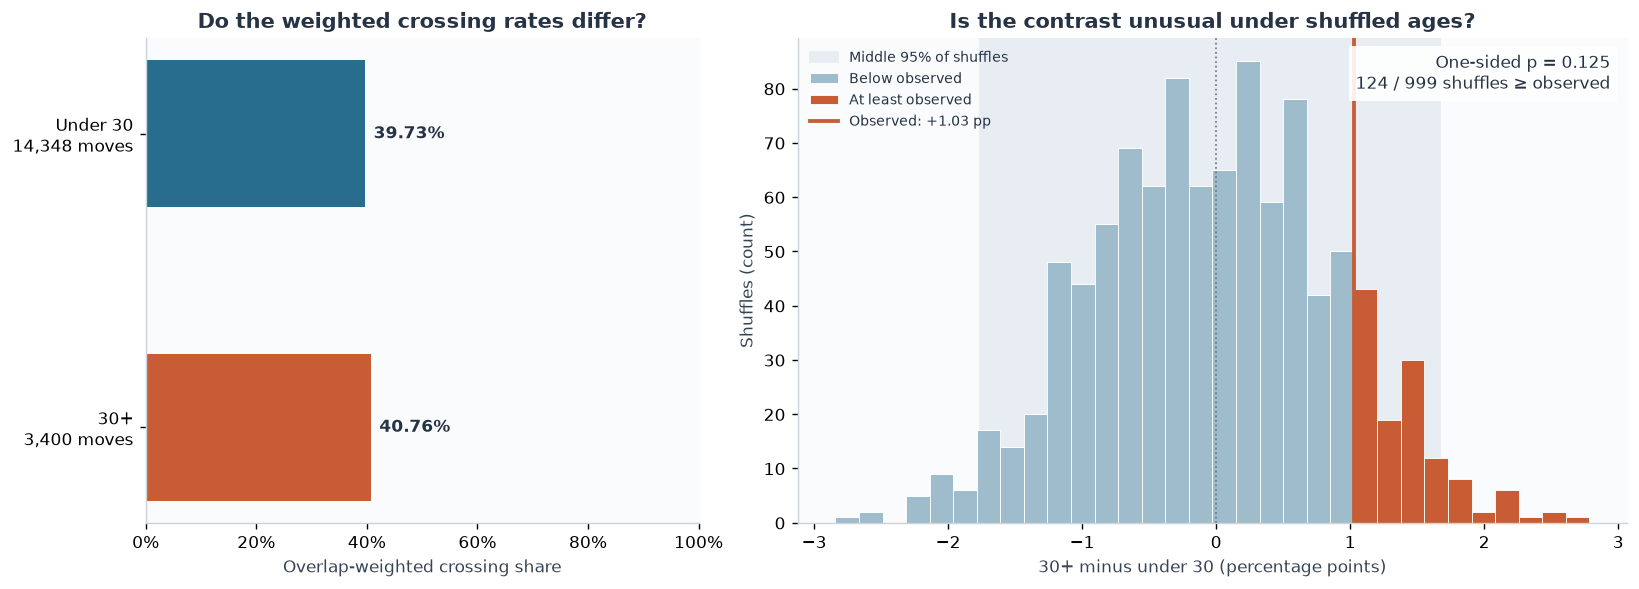

**Readout:** The observed difference is positive, but the shuffled comparison provides limited evidence for the proposed direction.

In [37]:
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

UNDER30_COLOR = '#286c8e'
AGE30PLUS_COLOR = '#c85d35'
VISUAL_STYLE = {
    'figure.facecolor': 'white', 'axes.facecolor': '#fafbfc',
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.labelcolor': '#354354', 'text.color': '#253344',
    'axes.edgecolor': '#cbd3da', 'grid.color': '#e4e9ee',
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 125,
}

with plt.rc_context(VISUAL_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6),
                             gridspec_kw={'width_ratios': [1, 1.5]}, layout='constrained')
    rates = [primary_result['rate_under30_percent'], primary_result['rate_30plus_percent']]
    axes[0].barh([0, 1], rates, height=0.5, color=[UNDER30_COLOR, AGE30PLUS_COLOR])
    axes[0].set(yticks=[0, 1], yticklabels=[
        f"Under 30\n{primary_result['n_under30']:,} moves",
        f"30+\n{primary_result['n_30plus']:,} moves"],
        xlim=(0, 100), xlabel='Overlap-weighted crossing share',
        title='Do the weighted crossing rates differ?')
    axes[0].invert_yaxis()
    axes[0].xaxis.set_major_formatter(PercentFormatter(100))
    for y, rate in enumerate(rates):
        axes[0].text(rate + 1.5, y, f'{rate:.2f}%', va='center', fontweight='bold')

    observed = primary_result['difference_pp']
    upper_tail = primary_null >= observed
    axes[1].axvspan(primary_result['null_2.5_percentile_pp'],
                   primary_result['null_97.5_percentile_pp'],
                   color='#e7edf2', label='Middle 95% of shuffles', zorder=0)
    axes[1].hist([primary_null[~upper_tail], primary_null[upper_tail]],
                 bins=np.histogram_bin_edges(primary_null, bins=32), stacked=True,
                 color=['#9ebccc', AGE30PLUS_COLOR], edgecolor='white', linewidth=0.5,
                 label=['Below observed', 'At least observed'])
    axes[1].axvline(0, color='#687582', linestyle=':', linewidth=1)
    axes[1].axvline(observed, color=AGE30PLUS_COLOR, linewidth=2.2,
                   label=f'Observed: {observed:+.2f} pp')
    axes[1].set(xlabel='30+ minus under 30 (percentage points)',
                ylabel='Shuffles (count)', title='Is the contrast unusual under shuffled ages?')
    axes[1].text(0.98, 0.97,
                 f"One-sided p = {primary_result['one_sided_p']:.3f}\n"
                 f'{upper_tail.sum():,} / {len(primary_null):,} shuffles ≥ observed',
                 transform=axes[1].transAxes, ha='right', va='top', fontsize=10,
                 bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.9})
    axes[1].legend(frameon=False, fontsize=8, loc='upper left')
    plt.show()
display(Markdown(f'**Readout:** {primary_interpretation}'))

### 2. Who is represented in that comparison?

**Look for:** the largest loss of records on the left, and age or
season differences in historical endpoint coverage on the right.
The left-hand bars are **successive subsets of the evaluation window**;
they do not combine the historical and evaluation branches. Right-hand
percentages use all evaluation moves in the named age group and season
as their denominator. The unknown-age record is only in the left panel.

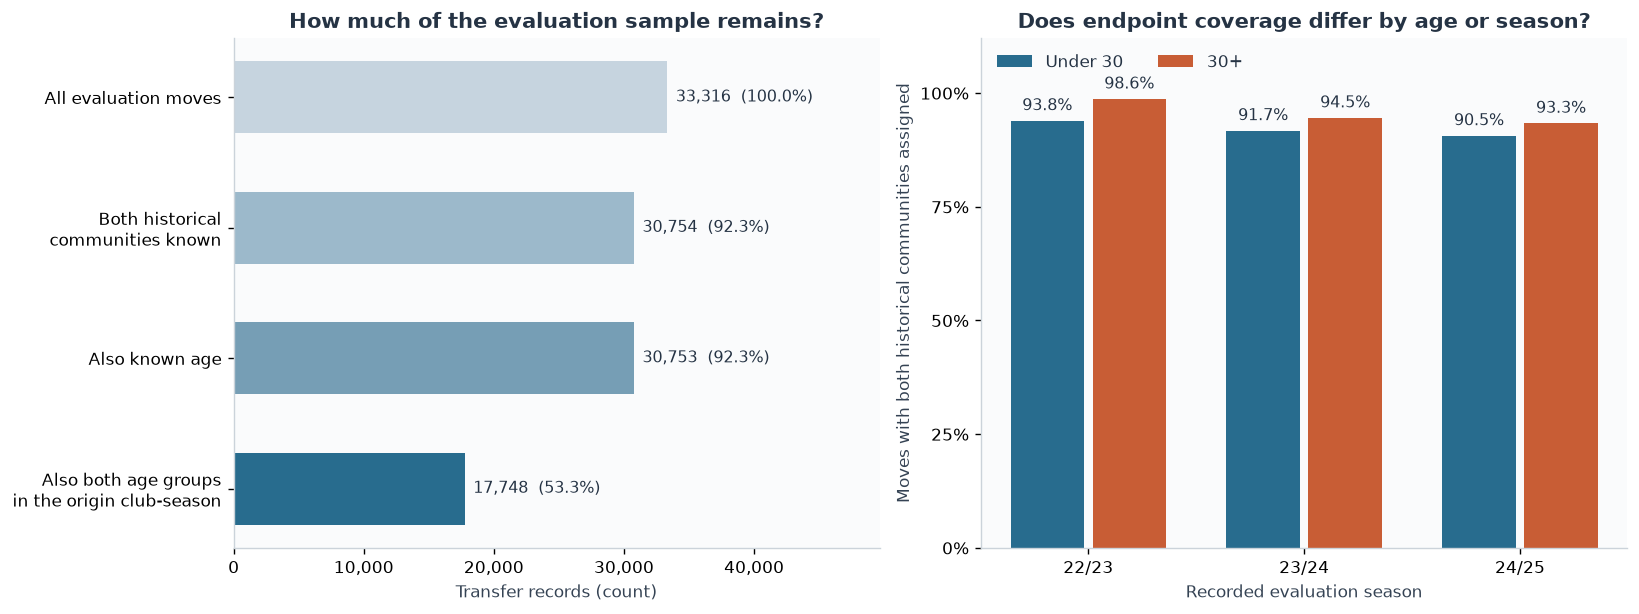

**Readout:** the final comparison retains **53.3%** of evaluation moves. Forming mixed-age club-seasons removes **13,005** otherwise age-known, historically covered moves. Check this selection before generalizing the result.

In [38]:
visual_counts = [len(evaluation), len(covered), len(eligible), len(comparison)]
visual_coverage = (coverage['endpoint_coverage_percent'].unstack('age_group')
                   .reindex(EVALUATION_SEASONS)[['Under 30', '30+']])
assert all(a >= b for a, b in zip(visual_counts, visual_counts[1:]))

with plt.rc_context(VISUAL_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout='constrained')
    axes[0].barh(range(4), visual_counts, height=0.55,
                 color=['#c6d4df', '#9cb9cb', '#769eb5', UNDER30_COLOR])
    axes[0].set(yticks=range(4), yticklabels=[
        'All evaluation moves', 'Both historical\ncommunities known',
        'Also known age', 'Also both age groups\nin the origin club-season'],
        xlim=(0, len(evaluation) * 1.49), xlabel='Transfer records (count)',
        title='How much of the evaluation sample remains?')
    axes[0].invert_yaxis()
    axes[0].xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    for y, count in enumerate(visual_counts):
        axes[0].text(count + len(evaluation) * 0.02, y,
                     f'{count:,}  ({100 * count / len(evaluation):.1f}%)', va='center', fontsize=9)

    x = np.arange(len(EVALUATION_SEASONS))
    for offset, group, color in [(-0.19, 'Under 30', UNDER30_COLOR), (0.19, '30+', AGE30PLUS_COLOR)]:
        bars = axes[1].bar(x + offset, visual_coverage[group], width=0.34, color=color, label=group)
        axes[1].bar_label(bars, labels=[f'{value:.1f}%' for value in visual_coverage[group]],
                          padding=4, fontsize=9)
    axes[1].set(xticks=x, xticklabels=EVALUATION_SEASONS, ylim=(0, 112),
                yticks=[0, 25, 50, 75, 100], xlabel='Recorded evaluation season',
                ylabel='Moves with both historical communities assigned',
                title='Does endpoint coverage differ by age or season?')
    axes[1].yaxis.set_major_formatter(PercentFormatter(100))
    axes[1].legend(frameon=False, loc='upper left', ncol=2)
    plt.show()
display(Markdown(
    f"**Readout:** the final comparison retains **{100 * len(comparison) / len(evaluation):.1f}%** "
    f"of evaluation moves. Forming mixed-age club-seasons removes **{len(eligible) - len(comparison):,}** "
    'otherwise age-known, historically covered moves. Check this selection before generalizing the result.'
))

### 3. Do the historical communities have a sensible structure?

**Look for:** very uneven community sizes, strong diagonal cells,
and substantial traffic between particular communities. Labels `C00`,
`C01`, … are the original community IDs, ordered by size; the example
club is the member with greatest incoming plus outgoing strength.
The matrix shows the **largest 20 communities only**, using **logarithmic
color** so small flows remain visible. White means zero. Rows are origins,
columns are destinations; diagonal cells are within-community transfers.
Community fitting and all counts here use historical transfers only.

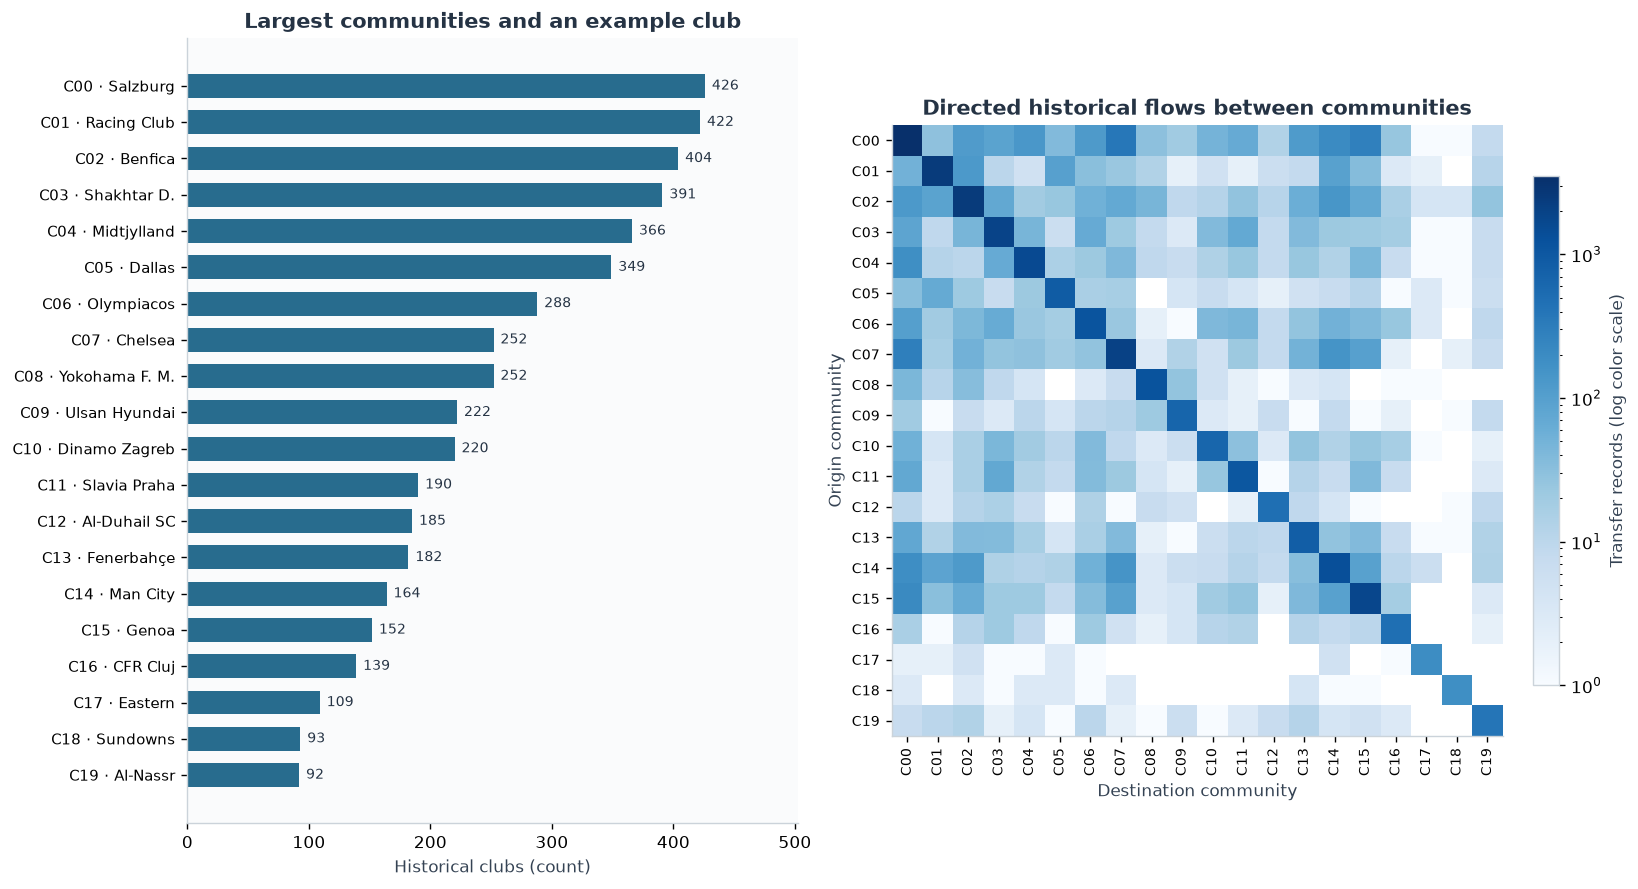

**Readout:** these 20 communities contain **4,898 / 5,410 clubs**. The matrix displays **33,890 / 34,405 historical moves** (both endpoints in the displayed communities). Across **all 196 communities**, **74.0%** of historical moves stay within their community. The diagonal is a diagnostic of the fitted partition, not an independent validation of it.

In [39]:
visual_top = community_sizes.head(20)
visual_flow_communities = flows.assign(
    origin=flows['from_club_id'].map(primary_map),
    destination=flows['to_club_id'].map(primary_map))
visual_matrix = (visual_flow_communities.pivot_table(
    index='origin', columns='destination', values='weight', aggfunc='sum', fill_value=0)
    .reindex(index=visual_top.index, columns=visual_top.index, fill_value=0))
visual_community_labels = [
    f"C{group_id:02d} · {club_names.loc[total_strength.loc[sorted(primary_communities[group_id])].idxmax()]}"
    for group_id in visual_top.index]
visual_within = visual_flow_communities.loc[
    visual_flow_communities['origin'].eq(visual_flow_communities['destination']), 'weight'].sum()

with plt.rc_context(VISUAL_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(13, 7), layout='constrained')
    bars = axes[0].barh(range(len(visual_top)), visual_top, color=UNDER30_COLOR, height=0.66)
    axes[0].bar_label(bars, padding=4, fontsize=8)
    axes[0].set(yticks=range(len(visual_top)), yticklabels=visual_community_labels,
                xlim=(0, visual_top.max() * 1.18), xlabel='Historical clubs (count)',
                title='Largest communities and an example club')
    axes[0].tick_params(axis='y', labelsize=8.5)
    axes[0].invert_yaxis()

    image = axes[1].imshow(np.ma.masked_equal(visual_matrix.to_numpy(dtype=float), 0),
                           cmap='Blues', norm=LogNorm(vmin=1, vmax=visual_matrix.to_numpy().max()))
    axes[1].set(xticks=range(len(visual_top)), yticks=range(len(visual_top)),
                xticklabels=[f'C{i:02d}' for i in visual_top.index],
                yticklabels=[f'C{i:02d}' for i in visual_top.index],
                xlabel='Destination community', ylabel='Origin community',
                title='Directed historical flows between communities')
    axes[1].set_facecolor('white')
    axes[1].tick_params(axis='x', labelrotation=90, labelsize=8)
    axes[1].tick_params(axis='y', labelsize=8)
    fig.colorbar(image, ax=axes[1], shrink=0.65, label='Transfer records (log color scale)')
    plt.show()
display(Markdown(
    f"**Readout:** these 20 communities contain **{visual_top.sum():,} / {graph.number_of_nodes():,} clubs**. "
    f"The matrix displays **{int(visual_matrix.to_numpy().sum()):,} / {len(historical):,} historical moves** "
    '(both endpoints in the displayed communities). '
    f"Across **all {len(primary_communities)} communities**, "
    f"**{100 * visual_within / len(historical):.1f}%** of historical moves stay within their community. "
    'The diagonal is a diagnostic of the fitted partition, not an independent validation of it.'
))

### 4. Could age imbalance, a single season, or a few clubs drive this?

**Look for:** changes in the age distribution after selection, sparse
older-player counts within club-seasons, seasonal sign changes, and
unusually large contributions from individual club-seasons.
Age histograms are normalized separately, so their shapes can be compared.
Seasonal dots reuse the stated overlap weights within that season; they
are descriptive estimates. Each contribution on the lower right equals
its club-season's weight share times its age difference. All contributions
sum to the primary result; only the eight largest absolute ones are shown.

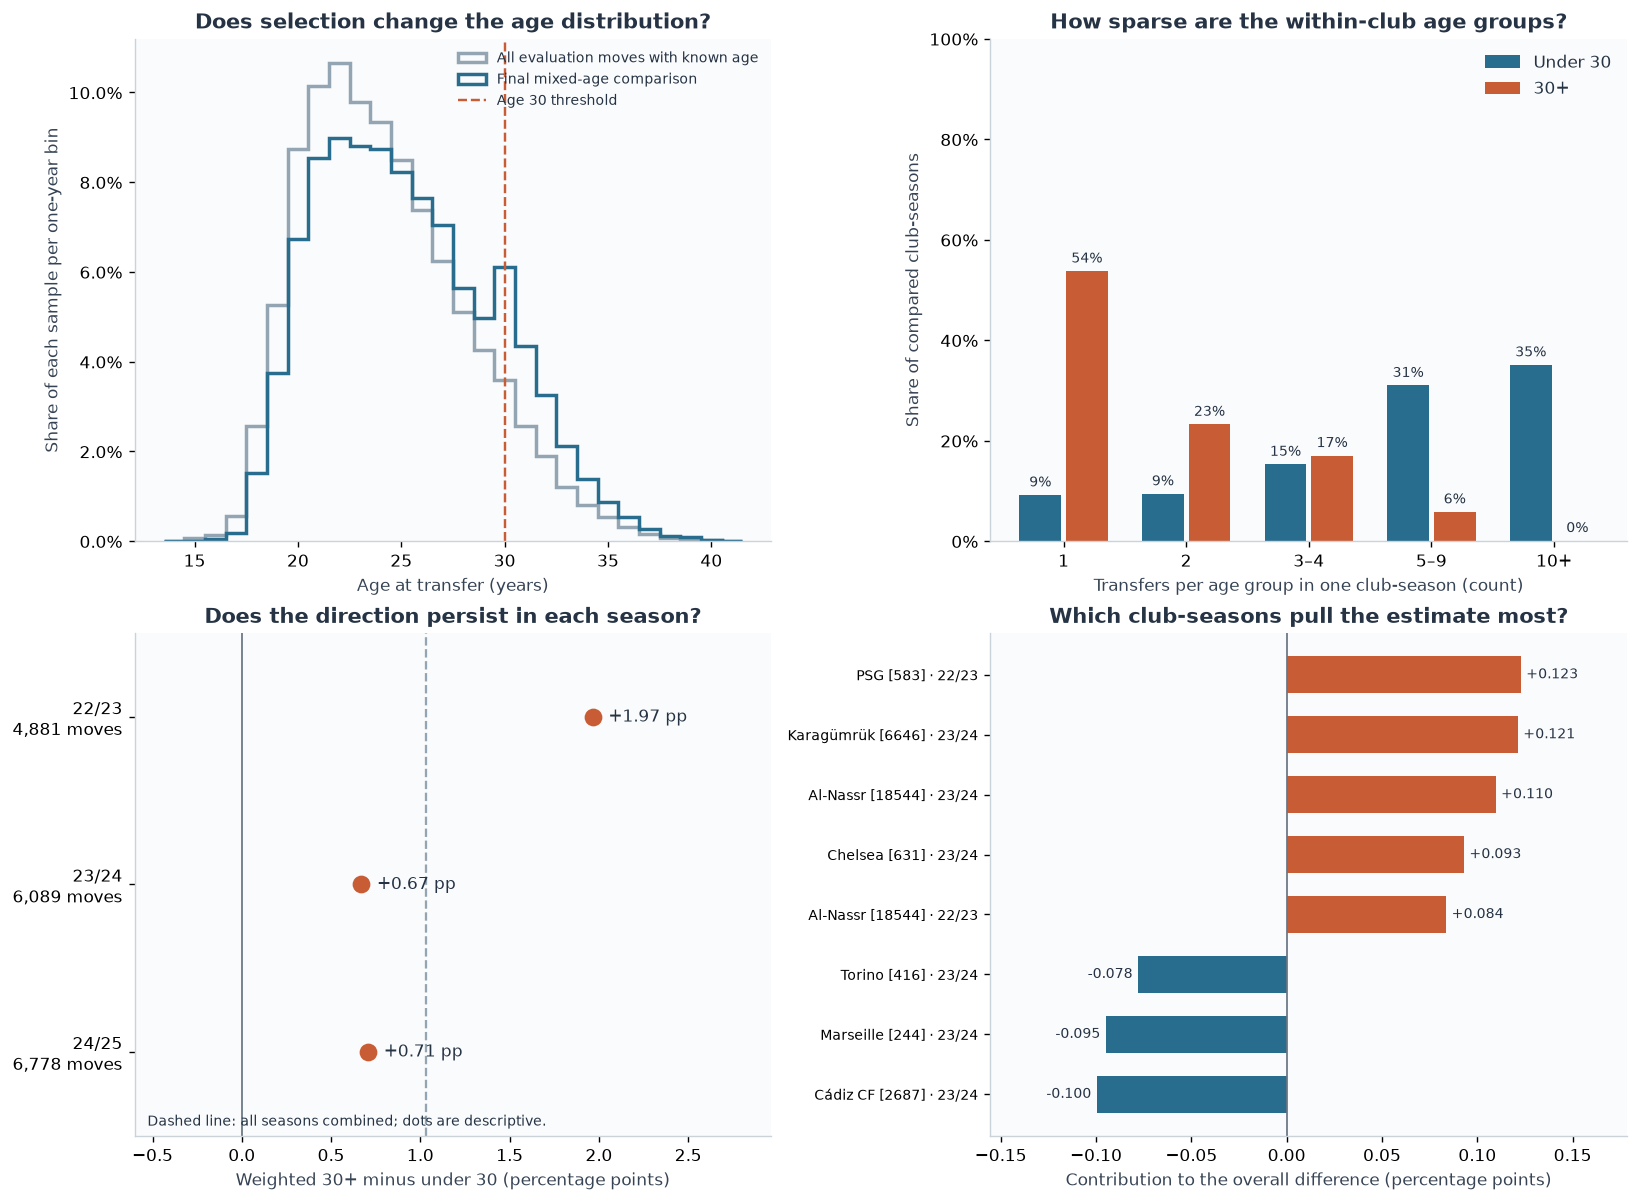

**Readout:** **53.8%** of compared club-seasons have only one 30+ move. They carry **29.9%** of the total overlap weight. The contribution and seasonal averages above both reconcile to the primary difference.

In [40]:
visual_age_bins = np.arange(np.floor(evaluation['age'].min()), np.ceil(evaluation['age'].max()) + 2) - 0.5
visual_count_labels = ['1', '2', '3–4', '5–9', '10+']
visual_group_counts = pd.DataFrame({
    group: pd.cut(primary_strata[column], bins=[0, 1, 2, 4, 9, np.inf],
                  labels=visual_count_labels).value_counts(sort=False)
    for group, column in [('Under 30', 'n_under30'), ('30+', 'n_30plus')]})
visual_seasons = pd.DataFrame([
    {'season': season, 'transfers': int(part['n_total'].sum()), 'weight': part['weight'].sum(),
     'difference_pp': 100 * np.average(part['rate_30plus'] - part['rate_under30'], weights=part['weight'])}
    for season in EVALUATION_SEASONS
    for part in [primary_strata.xs(season, level='transfer_season')]
])
visual_contributions = (100 * (primary_strata['rate_30plus'] - primary_strata['rate_under30'])
                        * primary_strata['weight'] / primary_strata['weight'].sum())
assert np.isclose(visual_contributions.sum(), primary_result['difference_pp'])
assert np.isclose(np.average(visual_seasons['difference_pp'], weights=visual_seasons['weight']),
                  primary_result['difference_pp'])
visual_influential = visual_contributions.loc[visual_contributions.abs().nlargest(8).index].sort_values()

with plt.rc_context(VISUAL_STYLE):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9.5), layout='constrained')
    for frame, label, color in [(evaluation, 'All evaluation moves with known age', '#93a4b2'),
                                 (comparison, 'Final mixed-age comparison', UNDER30_COLOR)]:
        ages = frame['age'].dropna().to_numpy(dtype=float)
        axes[0, 0].hist(ages, bins=visual_age_bins, weights=np.full(len(ages), 100 / len(ages)),
                        histtype='step', linewidth=2, color=color, label=label)
    axes[0, 0].axvline(30, color=AGE30PLUS_COLOR, linestyle='--', linewidth=1.4, label='Age 30 threshold')
    axes[0, 0].set(xlabel='Age at transfer (years)', ylabel='Share of each sample per one-year bin',
                   title='Does selection change the age distribution?')
    axes[0, 0].yaxis.set_major_formatter(PercentFormatter(100))
    axes[0, 0].legend(frameon=False, fontsize=8)

    x = np.arange(len(visual_count_labels))
    for offset, group, color in [(-0.19, 'Under 30', UNDER30_COLOR), (0.19, '30+', AGE30PLUS_COLOR)]:
        bars = axes[0, 1].bar(x + offset, 100 * visual_group_counts[group] / len(primary_strata),
                              width=0.34, color=color, label=group)
        axes[0, 1].bar_label(bars, fmt='%.0f%%', padding=3, fontsize=8)
    axes[0, 1].set(xticks=x, xticklabels=visual_count_labels, ylim=(0, 100),
                   xlabel='Transfers per age group in one club-season (count)',
                   ylabel='Share of compared club-seasons', title='How sparse are the within-club age groups?')
    axes[0, 1].yaxis.set_major_formatter(PercentFormatter(100))
    axes[0, 1].legend(frameon=False)

    axes[1, 0].axvline(0, color='#687582', linewidth=1)
    axes[1, 0].axvline(primary_result['difference_pp'], color='#93a4b2', linestyle='--', linewidth=1.3)
    axes[1, 0].scatter(visual_seasons['difference_pp'], range(len(visual_seasons)),
                       s=85, color=AGE30PLUS_COLOR, zorder=3)
    axes[1, 0].set(yticks=range(len(visual_seasons)), yticklabels=[
        f"{row.season}\n{row.transfers:,} moves" for row in visual_seasons.itertuples()],
        ylim=(len(visual_seasons) - 0.5, -0.5),
        xlim=(min(0, visual_seasons['difference_pp'].min()) - 0.6,
              max(0, visual_seasons['difference_pp'].max()) + 1),
        xlabel='Weighted 30+ minus under 30 (percentage points)', title='Does the direction persist in each season?')
    for y, value in enumerate(visual_seasons['difference_pp']):
        axes[1, 0].annotate(f'{value:+.2f} pp', (value, y), xytext=(9, 0),
                            textcoords='offset points', va='center', fontsize=10)
    axes[1, 0].text(0.02, 0.02, 'Dashed line: all seasons combined; dots are descriptive.',
                    transform=axes[1, 0].transAxes, fontsize=8)

    bars = axes[1, 1].barh(range(len(visual_influential)), visual_influential, height=0.62,
        color=[AGE30PLUS_COLOR if value > 0 else UNDER30_COLOR for value in visual_influential])
    axes[1, 1].bar_label(bars, labels=[f'{value:+.3f}' for value in visual_influential], padding=3, fontsize=8)
    axes[1, 1].axvline(0, color='#687582', linewidth=1)
    axes[1, 1].set(yticks=range(len(visual_influential)), yticklabels=[
        f'{club_names.loc[club]} [{club}] · {season}' for club, season in visual_influential.index],
        xlabel='Contribution to the overall difference (percentage points)',
        title='Which club-seasons pull the estimate most?')
    axes[1, 1].tick_params(axis='y', labelsize=8)
    axes[1, 1].margins(x=0.25)
    plt.show()
visual_one_older = primary_strata['n_30plus'].eq(1)
display(Markdown(
    f"**Readout:** **{100 * visual_one_older.mean():.1f}%** of compared club-seasons have only one 30+ move. "
    f"They carry **{100 * primary_strata.loc[visual_one_older, 'weight'].sum() / primary_strata['weight'].sum():.1f}%** "
    'of the total overlap weight. The contribution and seasonal averages above both reconcile to the primary difference.'
))

### 5. Does the answer survive reasonable alternative choices?

**Look for:** a sign change or a large shift in the observed dots.
Gray segments show the middle 95% of each **permutation null**;
orange dots show the observed difference. These segments are **not
effect confidence intervals**. Zero is marked by the vertical line.
NMI measures agreement with the primary communities (1 = identical).

The left panel changes communities on the **same transfers**. The right
panel keeps each player's earliest eligible move before rebuilding
mixed-age strata, so **both the sample and its club-seasons change**.
Both panels use the same horizontal scale. Infomap availability is
reported below the plot, as in the original analysis.

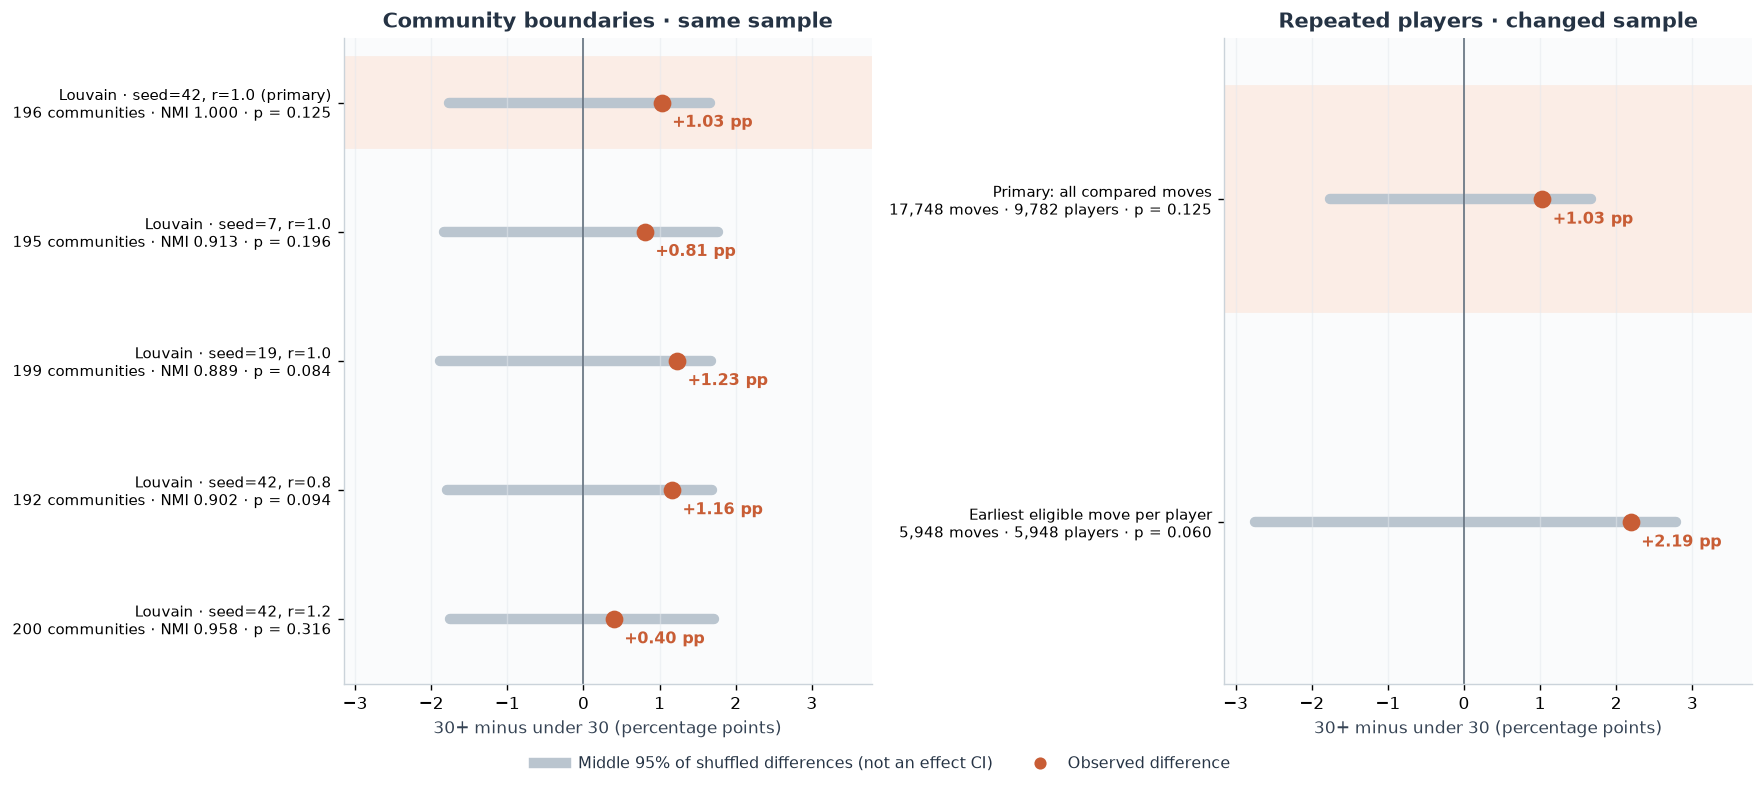

**Readout:** The contrast shrinks under alternative partitions, so the effect size is sensitive to the community definition. Infomap unavailable in this environment; Louvain checks are the reported partition sensitivity analysis.

In [41]:
visual_repeat = pd.DataFrame([primary_result, repeated_result])
visual_partition_labels = [
    f"{row.method} · {row.settings.replace('; resolution=', ', r=')}\n"
    f"{row.communities} communities · NMI {row.NMI_to_primary:.3f} · p = {row.one_sided_p:.3f}"
    for row in sensitivity.itertuples()]
visual_repeat_labels = [
    f"{label}\n{row.transfers:,} moves · {row.players:,} players · p = {row.one_sided_p:.3f}"
    for label, row in zip(['Primary: all compared moves', 'Earliest eligible move per player'],
                          visual_repeat.itertuples())]
visual_all_checks = pd.concat([sensitivity, visual_repeat], ignore_index=True)
visual_limits = (
    min(0, visual_all_checks['null_2.5_percentile_pp'].min(), visual_all_checks['difference_pp'].min()) - 0.4,
    max(0, visual_all_checks['null_97.5_percentile_pp'].max(), visual_all_checks['difference_pp'].max()) + 1)

with plt.rc_context(VISUAL_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), layout='constrained')
    for ax, frame, labels, title in [
        (axes[0], sensitivity, visual_partition_labels, 'Community boundaries · same sample'),
        (axes[1], visual_repeat, visual_repeat_labels, 'Repeated players · changed sample')]:
        ax.axhspan(-0.35, 0.35, color='#fbede6', zorder=0)
        ax.axvline(0, color='#687582', linewidth=1)
        for y, row in enumerate(frame.itertuples()):
            ax.plot([frame.iloc[y]['null_2.5_percentile_pp'], frame.iloc[y]['null_97.5_percentile_pp']],
                    [y, y], color='#bac5cf', linewidth=6, solid_capstyle='round', zorder=1)
            ax.scatter(row.difference_pp, y, color=AGE30PLUS_COLOR, s=85, zorder=3)
            ax.annotate(f'{row.difference_pp:+.2f} pp', (row.difference_pp, y), xytext=(6, -14),
                        textcoords='offset points', fontsize=9, color=AGE30PLUS_COLOR, fontweight='bold')
        ax.set(yticks=range(len(frame)), yticklabels=labels,
               ylim=(len(frame) - 0.5, -0.5), xlim=visual_limits,
               xlabel='30+ minus under 30 (percentage points)', title=title)
        ax.tick_params(axis='y', labelsize=8.5)
        ax.grid(axis='x', alpha=0.5)
    fig.legend(handles=[
        Line2D([0], [0], color='#bac5cf', linewidth=6, label='Middle 95% of shuffled differences (not an effect CI)'),
        Line2D([0], [0], marker='o', linestyle='none', color=AGE30PLUS_COLOR, label='Observed difference')],
        loc='outside lower center', ncol=2, frameon=False, fontsize=9)
    plt.show()
display(Markdown(f'**Readout:** {boundary_interpretation} {infomap_status}'))